# 04 · Modelagem e caracterização dos segmentos de RH

**CRISP-DM — Modelagem** · *IBM HR Analytics Employee Attrition & Performance*

**Entrada:** `base_rh_preprocessed.csv` (matriz de atributos do notebook 03) e `base_rh_perfil.csv` (variáveis originais e `Desligamento` somente para interpretação). Ambos devem preservar a mesma ordem de colaboradores.

Onze algoritmos de agrupamento são comparados usando silhueta euclidiana na **mesma matriz de atributos**; a seleção exige entre 2 e 8 grupos, maior grupo ≤ 90% e ruído ≤ 20%. Essas restrições são critérios heurísticos do estudo, não critérios universais de qualidade. Uma silhueta maior não assegura relevância de negócio: interpretar distribuição e perfis dos segmentos.

| Família | Algoritmos |
|---|---|
| Centroides / representantes | K-means, MiniBatchKMeans, BisectingKMeans, K-medianas (Manhattan), K-means com PCA branqueado, K-medoides |
| Hierárquica | Birch, Ward |
| Probabilística | Gaussian Mixture (GMM) |
| Densidade | Mean Shift, DBSCAN |

**Saídas:** modelo `.joblib`, resumo `selecionado_rh.json`, rótulos `segmentos_rh.csv`, perfil agregado `perfil_segmentos_rh.csv` e base por funcionário `colaboradores_segmentados_rh.csv`. `Desligamento` não participa da formação dos clusters.

In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.spatial.distance import cdist
from sklearn.base import BaseEstimator, ClusterMixin, clone
from sklearn.cluster import (KMeans, MiniBatchKMeans, BisectingKMeans, Birch,
                             AgglomerativeClustering, MeanShift, DBSCAN, estimate_bandwidth)
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import ParameterGrid
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline

BASE = Path('../data/processed')
MODELOS = Path('../models')

In [2]:
arquivo_matriz = BASE / 'base_rh_preprocessed.csv'
arquivo_perfil = BASE / 'base_rh_perfil.csv'
for arquivo in (arquivo_matriz, arquivo_perfil):
    if not arquivo.is_file():
        raise FileNotFoundError(f'Arquivo obrigatório ausente: {arquivo}. Execute o notebook 03 corrigido.')

matriz_df = pd.read_csv(arquivo_matriz, sep=';')
df = pd.read_csv(arquivo_perfil, sep=';')
if matriz_df.empty or matriz_df.columns.duplicated().any():
    raise ValueError('Matriz vazia ou com atributos duplicados.')
if len(matriz_df) != len(df):
    raise ValueError('A matriz e a base de perfil têm quantidades de linhas diferentes.')
if not all(pd.api.types.is_numeric_dtype(t) for t in matriz_df.dtypes):
    raise TypeError('A matriz do notebook 03 deve conter somente variáveis numéricas.')
if any('Desligamento' in c or 'Numero_do_Funcionario' in c for c in matriz_df.columns):
    raise ValueError('Desfecho ou identificador indevidamente presente nos atributos.')

COLUNAS_PERFIL = ['Idade', 'Renda_Mensal', 'Anos_na_Empresa', 'Desligamento']
faltando = [c for c in COLUNAS_PERFIL if c not in df.columns]
if faltando:
    raise ValueError(f'Colunas necessárias ao perfil dos segmentos ausentes: {faltando}')

X = matriz_df.to_numpy(dtype=float)
if not np.isfinite(X).all():
    raise ValueError('A matriz contém NaN ou valores infinitos.')
if ((X < -1e-12) | (X > 1 + 1e-12)).any():
    raise ValueError('A matriz contém valores fora do intervalo [0,1].')
D = cdist(X, X, metric='euclidean')
print(f'Matriz atual do notebook 03: {X.shape[0]} registros × {X.shape[1]} atributos')
print(f'Base para interpretação: {df.shape[0]} registros × {df.shape[1]} colunas')

Matriz atual do notebook 03: 1470 registros × 51 atributos
Base para interpretação: 1470 registros × 33 colunas


## Modelos que o scikit-learn não traz

As duas classes seguem a interface do scikit-learn (`fit` e `fit_predict`) e por isso entram na mesma varredura dos demais.

In [3]:
class KMedianas(BaseEstimator, ClusterMixin):
    """K-Means com distância Manhattan: atribui pela L1 e o centro vira a mediana."""

    def __init__(self, n_clusters=3, n_init=10, max_iter=100, random_state=42):
        self.n_clusters = n_clusters
        self.n_init = n_init
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        rng = np.random.default_rng(self.random_state)
        melhor = np.inf
        for _ in range(self.n_init):                                          
            centros = X[rng.choice(len(X), self.n_clusters, replace=False)]  
            for _ in range(self.max_iter):
                rotulos = cdist(X, centros, 'cityblock').argmin(axis=1)      
                novos = np.array([np.median(X[rotulos == g], axis=0) if (rotulos == g).any() else centros[g]
                                  for g in range(self.n_clusters)])           
                if np.allclose(novos, centros):                              
                    break
                centros = novos
            dist = cdist(X, centros, 'cityblock')
            custo = dist.min(axis=1).sum()                                   
            if custo < melhor:
                melhor, self.labels_, self.cluster_centers_ = custo, dist.argmin(axis=1), centros
        return self


class KMedoides(BaseEstimator, ClusterMixin):
    """Centro = um colaborador real (medoide): o de menor soma de distâncias ao próprio grupo."""

    def __init__(self, n_clusters=3, n_init=5, max_iter=100, random_state=42):
        self.n_clusters = n_clusters
        self.n_init = n_init
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, X, y=None):
        dist = cdist(X, X)                                                   
        rng = np.random.default_rng(self.random_state)
        melhor = np.inf
        for _ in range(self.n_init):
            medoides = rng.choice(len(dist), self.n_clusters, replace=False)  
            for _ in range(self.max_iter):
                rotulos = dist[:, medoides].argmin(axis=1)                   
                novos = medoides.copy()
                for g in range(self.n_clusters):
                    membros = np.flatnonzero(rotulos == g)
                    if len(membros):                                         
                        novos[g] = membros[dist[np.ix_(membros, membros)].sum(axis=1).argmin()]
                if np.array_equal(novos, medoides):                          
                    break
                medoides = novos
            custo = dist[:, medoides].min(axis=1).sum()                      
            if custo < melhor:
                melhor, self.labels_, self.medoid_indices_ = custo, dist[:, medoides].argmin(axis=1), medoides
        return self

## Escalas dos parâmetros

Mahalanobis, Mean Shift e DBSCAN dependem da escala das distâncias. Por isso a grade de cada um é tirada dos próprios dados, e não fixada à mão.

In [4]:
s = np.linalg.svd(X - X.mean(axis=0), compute_uv=False)
posto = int((s**2 > 1e-10 * s[0]**2).sum())
if posto < 1:
    raise ValueError('Matriz sem variabilidade para clusterização.')

larguras = sorted({round(float(estimate_bandwidth(X, quantile=q, n_samples=min(1000, len(X)), random_state=42)), 2)
                   for q in (0.1, 0.2, 0.3, 0.5)}, reverse=True)
larguras = [v for v in larguras if v > 0]
if not larguras:
    raise ValueError('Não foi possível estimar bandwidths positivos para Mean Shift.')

n_vizinhos = min(11, len(X))
dist_vizinho = NearestNeighbors(n_neighbors=n_vizinhos).fit(X).kneighbors(X)[0][:, -1]
raios = sorted(set(round(float(np.percentile(dist_vizinho, p)), 2) for p in (50, 70, 80, 90, 95)))
raios = [v for v in raios if v > 0]
if not raios:
    raise ValueError('Não foi possível estimar raios positivos para DBSCAN.')
print(f'Posto: {posto} de {X.shape[1]} · bandwidths: {larguras} · eps: {raios}')

Posto: 44 de 51 · bandwidths: [3.38, 3.15, 3.0, 2.78] · eps: [2.07, 2.22, 2.32, 2.44, 2.53]


In [5]:
k = [2, 3, 4, 5, 6, 8]  

models = [  
    ('k-means', KMeans(n_init=10, random_state=42), {'n_clusters': k, 'init': ['k-means++', 'random']}),
    ('mini batch k-means', MiniBatchKMeans(n_init=10, random_state=42), {'n_clusters': k, 'batch_size': [64, 128, 256]}),
    ('bisecting k-means', BisectingKMeans(random_state=42), {'n_clusters': k, 'bisecting_strategy': ['biggest_inertia', 'largest_cluster']}),
    ('birch', Birch(), {'n_clusters': k, 'threshold': [0.5, 1.0, 2.0]}),
    ('k-means manhattan', KMedianas(), {'n_clusters': k}),  
    ('k-means mahalanobis', Pipeline([
        ('branqueamento', PCA(n_components=posto, whiten=True, svd_solver='full')),  
        ('kmeans', KMeans(n_init=10, random_state=42)),
    ]), {'kmeans__n_clusters': k}),
    ('k-medoids', KMedoides(), {'n_clusters': k}),  
    ('gaussian mixture', GaussianMixture(reg_covar=1e-3, max_iter=200, random_state=42),
     {'n_components': k, 'covariance_type': ['full', 'diag']}),  
    ('ward', AgglomerativeClustering(linkage='ward'), {'n_clusters': k}),  
    ('mean shift', MeanShift(n_jobs=-1), {'bandwidth': larguras}),       
    ('dbscan', DBSCAN(min_samples=10), {'eps': raios}),                   
]

## Varredura e comparação

As configurações são ajustadas sobre toda a base, sem rótulos supervisionados. A silhueta é medida sempre no espaço **euclidiano original** dos atributos preparados, inclusive para algoritmos que empregam outra métrica internamente. Para DBSCAN, o cálculo ignora ruído (`-1`), enquanto a proporção de ruído permanece critério de seleção. Essa escolha torna os valores comparáveis segundo uma única métrica, mas não avalia separadamente a qualidade do ruído.

A execução integral da grade pode ser demorada, sobretudo em K-medoides, Mean Shift e nas avaliações da silhueta. Os resultados são da matriz carregada nesta execução, não de saídas persistidas em versões antigas do notebook.

In [6]:
linhas = []
for nome, modelo, grade in models:
    inicio_modelo = time.perf_counter()
    for params in ParameterGrid(grade):
        inicio = time.perf_counter()
        labels = np.asarray(clone(modelo).set_params(**params).fit_predict(X))
        validos = labels >= 0
        n_validos = int(validos.sum())
        grupos = int(len(np.unique(labels[validos])))
        silhueta = np.nan
        if 2 <= grupos < n_validos:
            silhueta = float(silhouette_score(D[np.ix_(validos, validos)],
                                               labels[validos], metric='precomputed'))
        proporcoes = pd.Series(labels[validos]).value_counts(normalize=True)
        linhas.append({
            'modelo': nome,
            'params': params,
            'grupos': grupos,
            'silhueta': silhueta,
            'maior_grupo': float(proporcoes.max()) if n_validos else np.nan,
            'ruido': float(1 - validos.mean()),
            'segundos': float(time.perf_counter() - inicio),
        })
    print(f'{nome}: {time.perf_counter() - inicio_modelo:.1f}s')

varredura = pd.DataFrame(linhas)

k-means: 4.3s
mini batch k-means: 4.3s
bisecting k-means: 0.7s
birch: 4.8s
k-means manhattan: 3.3s
k-means mahalanobis: 1.2s
k-medoids: 3.4s
gaussian mixture: 2.2s
ward: 1.2s
mean shift: 24.6s
dbscan: 0.2s


In [7]:
aprovados = (
    varredura
    .query('2 <= grupos <= 8')
    .query('maior_grupo <= 0.9')
    .query('ruido <= 0.2')
    .dropna(subset=['silhueta'])
    .sort_values('silhueta', ascending=False)
)
if aprovados.empty:
    raise ValueError('Nenhuma configuração satisfez os critérios de seleção. Revise os resultados antes de ajustar os limites.')
resumo = aprovados.drop_duplicates('modelo').set_index('modelo')
winner = resumo.index[0]

display(resumo.style.format({'silhueta': '{:.3f}', 'maior_grupo': '{:.1%}', 'ruido': '{:.1%}', 'segundos': '{:.1f}'}))
print(f'Sem configuração aprovada: {sorted(set(varredura.modelo) - set(resumo.index)) or "nenhuma"}')
print(f'Melhor modelo: {winner}')

,params,grupos,silhueta,maior_grupo,ruido,segundos
modelo,,,,,,
dbscan,{'eps': 2.07},3,0.114,67.8%,16.4%,0.1
mini batch k-means,"{'batch_size': 256, 'n_clusters': 2}",2,0.114,69.3%,0.0%,0.1
k-means,"{'init': 'k-means++', 'n_clusters': 2}",2,0.113,69.7%,0.0%,0.2
gaussian mixture,"{'covariance_type': 'full', 'n_components': 2}",2,0.113,69.7%,0.0%,0.1
k-medoids,{'n_clusters': 2},2,0.112,67.2%,0.0%,0.6
birch,"{'n_clusters': 2, 'threshold': 1.0}",2,0.107,71.8%,0.0%,0.2
ward,{'n_clusters': 2},2,0.106,71.8%,0.0%,0.4
bisecting k-means,"{'bisecting_strategy': 'biggest_inertia', 'n_clusters': 2}",2,0.088,60.0%,0.0%,0.1
k-means manhattan,{'n_clusters': 3},3,0.079,41.2%,0.0%,0.3


Sem configuração aprovada: ['mean shift']
Melhor modelo: dbscan


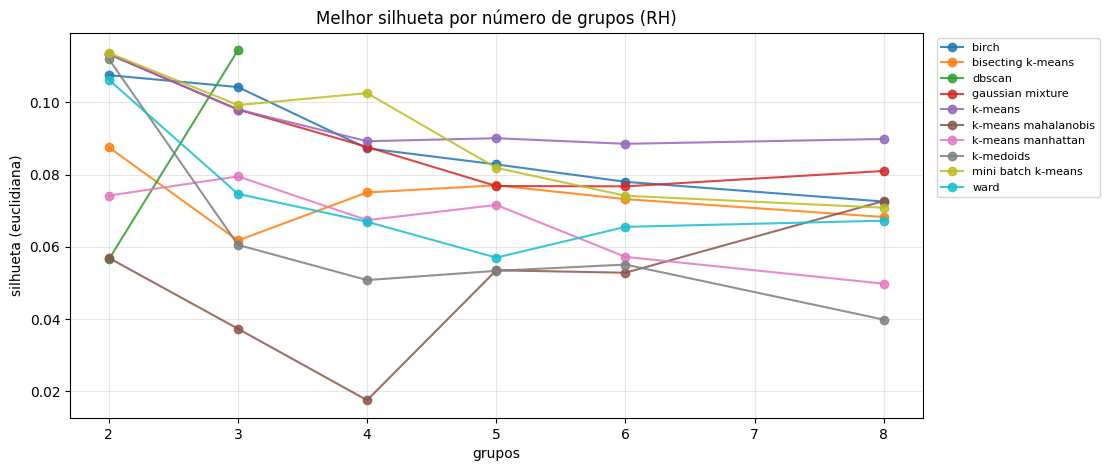

In [8]:
curvas = (
    varredura.query('2 <= grupos <= 10')                  
    .groupby(['grupos', 'modelo'])['silhueta'].max()      
    .unstack('modelo')
)
ax = curvas.plot(marker='o', figsize=(11, 5), alpha=0.85)
ax.set(title='Melhor silhueta por número de grupos (RH)', xlabel='grupos', ylabel='silhueta (euclidiana)')
ax.grid(alpha=0.3)
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

In [9]:
modelo, params = dict((n, m) for n, m, _ in models)[winner], resumo.loc[winner, 'params']  
final = clone(modelo).set_params(**params)  
labels = final.fit_predict(X)               

print(f'Parâmetros ótimos: {params}')
print(f'Silhueta alcançada: {resumo.loc[winner, "silhueta"]:.3f}')
print(f'Total de segmentos: {resumo.loc[winner, "grupos"]}')

Parâmetros ótimos: {'eps': 2.07}
Silhueta alcançada: 0.114
Total de segmentos: 3


In [10]:
# Perfil gerado a partir dos dados de interpretação do notebook 03,
# sem utilizar Desligamento na formação dos clusters.
if len(labels) != len(df):
    raise AssertionError('Número de rótulos diferente do número de funcionários.')

colaboradores_segmentados = df.copy()
colaboradores_segmentados['segmento'] = labels
perfil = (
    colaboradores_segmentados
    .groupby('segmento', dropna=False)
    .agg(colaboradores=('Idade', 'size'),
         renda_mediana=('Renda_Mensal', 'median'),
         idade_mediana=('Idade', 'median'),
         tempo_empresa=('Anos_na_Empresa', 'median'))
    .assign(participacao=lambda d: d['colaboradores'] / len(df))
    .sort_values('renda_mediana', ascending=False)
)
# Taxa de desligamento é descritiva (externa ao agrupamento).
desligamento = colaboradores_segmentados['Desligamento'].astype(str).str.strip().str.lower()
if not desligamento.isin(['sim', 'não', 'nao']).all():
    raise ValueError('Valores inesperados em Desligamento; revise os rótulos antes de calcular as taxas.')
colaboradores_segmentados['desligamento_binario'] = desligamento.eq('sim').astype(int)
perfil['taxa_desligamento'] = colaboradores_segmentados.groupby('segmento')['desligamento_binario'].mean()
print(perfil.to_string())

          colaboradores  renda_mediana  idade_mediana  tempo_empresa  participacao  taxa_desligamento
segmento                                                                                             
-1                  241         9756.0           40.0            7.0      0.163946           0.186722
 1                  374         5885.5           35.0            5.5      0.254422           0.184492
 0                  833         3986.0           35.0            5.0      0.566667           0.141657
 2                   22         3668.5           34.0            4.0      0.014966           0.227273


In [11]:
MODELOS.mkdir(parents=True, exist_ok=True)
BASE.mkdir(parents=True, exist_ok=True)
modelo_path = MODELOS / f"model_rh_{winner.replace(' ', '_').replace('-', '_')}.joblib"
joblib.dump(final, modelo_path)

pd.DataFrame({'segmento': labels}).to_csv(BASE / 'segmentos_rh.csv', sep=';', index=False)
perfil.to_csv(BASE / 'perfil_segmentos_rh.csv', sep=';')
colaboradores_segmentados.to_csv(BASE / 'colaboradores_segmentados_rh.csv', sep=';', index=False)

resumo_modelo = {
    'modelo': winner,
    'params': {k: (v.item() if isinstance(v, np.generic) else v) for k, v in params.items()},
    'grupos': int(resumo.loc[winner, 'grupos']),
    'silhueta': float(resumo.loc[winner, 'silhueta']),
    'arquivo': modelo_path.name,
    'n_amostras': int(X.shape[0]),
    'n_atributos': int(X.shape[1]),
    'atributos': matriz_df.columns.tolist(),
    'criterios': {'grupos_min': 2, 'grupos_max': 8, 'maior_grupo_max': 0.9, 'ruido_max': 0.2},
    'suporta_predicao_de_novos_casos': bool(hasattr(final, 'predict')),
}
(MODELOS / 'selecionado_rh.json').write_text(json.dumps(resumo_modelo, ensure_ascii=False, indent=2), encoding='utf-8')

assert len(pd.read_csv(BASE / 'segmentos_rh.csv', sep=';')) == len(df)
assert len(pd.read_csv(BASE / 'colaboradores_segmentados_rh.csv', sep=';')) == len(df)
print(f'Modelo salvo: {modelo_path}; perfis e rótulos em {BASE}; metadados em {MODELOS / "selecionado_rh.json"}')

Modelo salvo: ..\models\model_rh_dbscan.joblib; perfis e rótulos em ..\data\processed; metadados em ..\models\selecionado_rh.json
